# Minimizing the Ground State Energy of LiH
This program uses VQE to find the ground state of LiH. This program compares three different ansats to optimze the parameters used to find the energy.

In [ ]:
%pip -q install "qiskit>=1.2,<3" "qiskit-nature==0.7.2" pyscf scipy matplotlib
import numpy as np #python library
import matplotlib.pyplot as plt #python library for plotting

from scipy.optimize import minimize #importing classical optimizer

from qiskit import QuantumCircuit #importing quantum circuit class
from qiskit.quantum_info import SparsePauliOp, Statevector #importing make of Hamiltonian
from qiskit.visualization import plot_bloch_multivector, plot_histogram, array_to_latex

In [ ]:
def make_state(theta):
    """Rotate one qbit and then rotate the other."""

    qc = QuantumCircuit(2)

    qc.ry(theta[0], 0)  # Extract the scalar from the array
    qc.cx(0, 1)

    return Statevector(qc)

def make_state2(theta):
    """Returns an entangled state parameterized by a rotation angle theta."""
    qc = QuantumCircuit(2)

    # 1. Rotate qubit 0 by theta to create a variable superposition
    qc.ry(theta[0], 0)
    qc.ry(theta[1], 1)
    # 2. Entangle qubit 0 (control) with qubit 1 (target)
    qc.cx(0, 1)

    # Calculate the quantum state produced by qc and return it back to the function
    return Statevector(qc)

def make_state3(theta):
    """Prepare a two-qubit trial state."""
    qc = QuantumCircuit(2)

    qc.ry(theta[0], 0)

    qc.cx(0, 1)

    # Does rotating after the CNOT improve VQE?
    qc.ry(theta[1], 0)

    return Statevector(qc)

def make_state4(theta):
    """Prepare a two-qubit trial state."""
    qc = QuantumCircuit(2)

    qc.rx(theta[0], 0)

    qc.rx(theta[2], 1)

    qc.rz(theta[1], 1)

    qc.rz(theta[3], 1)

    # Does rotating after the CNOT improve VQE?
    qc.cx(0, 1)

    return Statevector(qc)


def energy(theta, statecall):
    '''Returns the expectation value for the iteration and stores it.'''
    state = statecall(theta)

    value = np.real(
        state.expectation_value(LIH)
    )

    energy_history.append(value)
    return value

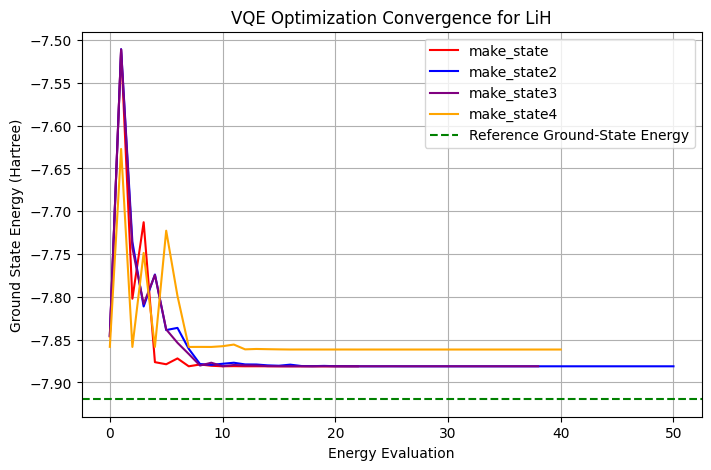

In [ ]:

# =====================================================
# Simple LiH Hamiltonian (Jordan-Wigner mapped)
# bond length ≈ 1.595 Å
# Converting into Pauli, using values from a data space using Sparse Pauli.
# It is stored as an array.
# =====================================================

LIH = SparsePauliOp.from_list([
    ("II", -7.4415091079),
    ("ZI", -0.2139867776),
    ("IZ", -0.2139867776),
    ("ZZ",  0.0079749198),
    ("XX",  0.1309840697),
    ("IX", -0.0009323605),
    ("XI", -0.0009323605),
    ("XZ", -0.0006035813),
    ("ZX", -0.0006035813)
])
energy_history = []
true_energy = -7.91957

result1 = minimize(
    energy, x0=[0.1], args=(make_state,), method="COBYLA"
)
history1 = energy_history.copy()

energy_history.clear()
result2 = minimize(
    energy, x0=[0.1, 0.1], args=(make_state2,), method="COBYLA"
)
history2 = energy_history.copy()

energy_history.clear()
result3 = minimize(
    energy, x0=[0.1, 0.1], args=(make_state3,), method="COBYLA"
)
history3 = energy_history.copy()

energy_history.clear()
result4 = minimize(
    energy, x0=[0.1, 0.1, 0.1, 0.1], args=(make_state4,), method="COBYLA"
)
history4 = energy_history.copy()

# Plot all four
plt.figure(figsize=(8,5))
plt.plot(history1, color="red", label="make_state")
plt.plot(history2, color="blue", label="make_state2")
plt.plot(history3, color="purple", label="make_state3")
plt.plot(history4, color="orange", label="make_state4")

plt.axhline(
    y=true_energy, color="green", linestyle="--",
    label="Reference Ground-State Energy"
)

plt.xlabel("Energy Evaluation")
plt.ylabel("Ground State Energy (Hartree)")
plt.title("VQE Optimization Convergence for LiH")
plt.legend()
plt.grid(True)
plt.show()